### ResNet MODEL FOR PNEUMONIA PREDICTION WITH EXPLAINABLE AI(HEATMAPS AND CONFIDANCE SCORES)

#### Importing Libraries

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

#### Loading Pre-trained Base

In [2]:
base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_resnet.trainable = False

#### Adding a Custom Classification Head

In [3]:
x = base_resnet.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
resnet_predictions = Dense(1, activation='sigmoid')(x)

resnet_model = Model(inputs=base_resnet.input, outputs=resnet_predictions)

#### Compling Model

In [4]:
resnet_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

#### Defining Callbacks

In [5]:
# Same as my Custom CNN for fair comparison)
checkpoint_resnet = ModelCheckpoint('best_resnet50.keras', monitor='val_accuracy', save_best_only=True, mode='max')
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.00001)
print("ResNet-50 Model Compiled. Ready to train.")

ResNet-50 Model Compiled. Ready to train.


#### Initializing Data Generators

In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Define paths
train_dir = r'chest_xray/train'
test_dir = r'chest_xray/test'

# 2. Parameters
IMG_SIZE = 224  
BATCH_SIZE = 32

# 3. Data Generator with 20% Validation Split
# This creates the validation set directly from the 5,216 images in 'train_dir'
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,  
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

# 4. Create Training Generator (80% subset)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training' 
)

# 5. Create Validation Generator (20% subset)
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

# 6. Create Test Generator
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f"\nData successfully split:")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {validation_generator.samples}")

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Data successfully split:
Training samples: 4173
Validation samples: 1043


#### Training Model

In [8]:
# Train ResNet-50
history_resnet = resnet_model.fit(
    train_generator,
    epochs=50,
    validation_data=validation_generator, 
    callbacks=[checkpoint_resnet, early_stop, reduce_lr]
)

Epoch 1/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - accuracy: 0.8222 - loss: 0.3658 - val_accuracy: 0.8025 - val_loss: 0.3756 - learning_rate: 2.0000e-04
Epoch 2/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 310s 2s/step - accuracy: 0.8203 - loss: 0.3716 - val_accuracy: 0.8054 - val_loss: 0.3761 - learning_rate: 2.0000e-04
Epoch 3/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 309s 2s/step - accuracy: 0.8112 - loss: 0.3761 - val_accuracy: 0.7919 - val_loss: 0.3891 - learning_rate: 2.0000e-04
Epoch 4/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - accuracy: 0.8234 - loss: 0.3673 - val_accuracy: 0.7872 - val_loss: 0.3834 - learning_rate: 2.0000e-04
Epoch 5/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - accuracy: 0.8287 - loss: 0.3607 - val_accuracy: 0.8054 - val_loss: 0.3819 - learning_rate: 4.0000e-05
Epoch 6/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.8193 - loss: 0.3741 - val_accuracy: 0.7987 - val_loss: 0.3815 - learning_rate: 4.0000e-05


#### Plotting Training History 

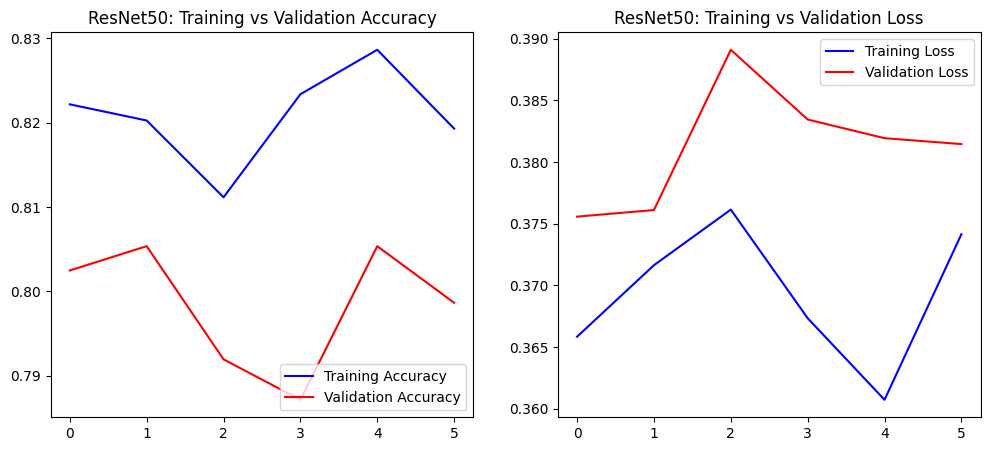

In [9]:
import matplotlib.pyplot as plt

def plot_resnet_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', color='blue')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='red')
    plt.title('ResNet50: Training vs Validation Accuracy')
    plt.legend(loc='lower right')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', color='blue')
    plt.plot(epochs_range, val_loss, label='Validation Loss', color='red')
    plt.title('ResNet50: Training vs Validation Loss')
    plt.legend(loc='upper right')
    
    plt.show()

plot_resnet_history(history_resnet)

#### Evaluating Model on Test Data

In [11]:
# Final ResNet-50 test evaluation
print("Evaluating ResNet50 on the unseen test set...")
test_loss, test_acc = resnet_model.evaluate(test_generator, verbose=1)
print(f"\n--- ResNet50 Final Test Accuracy: {test_acc:.2%} ---")

Evaluating ResNet50 on the unseen test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.7804 - loss: 0.4783

--- ResNet50 Final Test Accuracy: 78.04% ---


#### DETAILED EVAULATION METRICS

20/20 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step


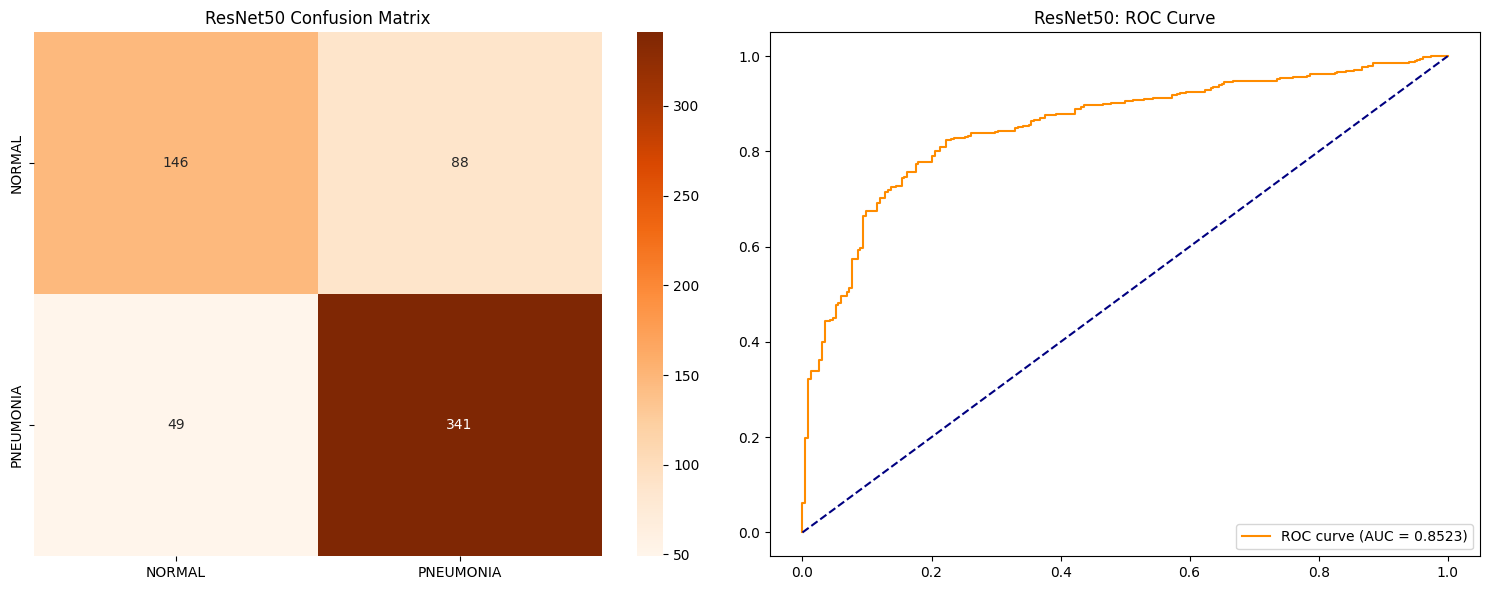


--- ResNet50 Classification Report ---
              precision    recall  f1-score   support

      NORMAL       0.75      0.62      0.68       234
   PNEUMONIA       0.79      0.87      0.83       390

    accuracy                           0.78       624
   macro avg       0.77      0.75      0.76       624
weighted avg       0.78      0.78      0.78       624



In [10]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import seaborn as sns
import numpy as np

# 1. Generate Predictions
test_generator.reset()
preds = resnet_model.predict(test_generator)
y_pred = (preds > 0.5).astype(int)
y_true = test_generator.classes

# 2. Visualization
plt.figure(figsize=(15, 6))

# Confusion Matrix
plt.subplot(1, 2, 1)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['NORMAL', 'PNEUMONIA'], yticklabels=['NORMAL', 'PNEUMONIA'])
plt.title('ResNet50 Confusion Matrix')

# ROC Curve
plt.subplot(1, 2, 2)
fpr, tpr, _ = roc_curve(y_true, preds)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.title('ResNet50: ROC Curve')
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

print("\n--- ResNet50 Classification Report ---")
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))

#### Implementing GradCAM

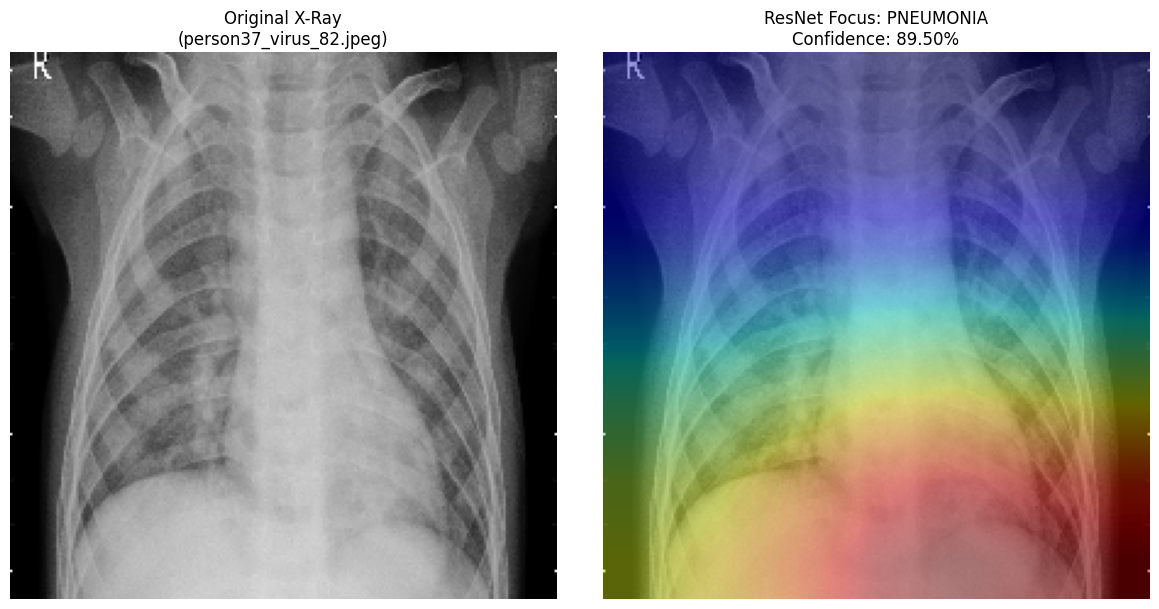

In [16]:
import cv2
import matplotlib.cm as cm
import os
import random

def get_resnet_gradcam(img_array, model, last_conv_layer_name="conv5_block3_out"):
    # Define the grad model targeting the final ResNet block
    grad_model = tf.keras.models.Model(
        inputs=model.input, 
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        class_channel = preds[:, 0]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    heatmap = last_conv_layer_output[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap).numpy()
    
    # Apply Center-Focus Mask
    h, w = heatmap.shape
    y, x = np.ogrid[:h, :w]
    mask = np.exp(-((x - w/2)**2 / (2 * (w/3)**2) + (y - h/2)**2 / (2 * (h/3)**2)))
    heatmap = np.maximum(heatmap, 0) * mask
    heatmap /= (np.max(heatmap) + 1e-10)
    return heatmap

# EXECUTION
p_dir = os.path.join(test_dir, 'PNEUMONIA')
sample_file = random.choice(os.listdir(p_dir))
img_path = os.path.join(p_dir, sample_file)
file_name_only = os.path.basename(img_path)

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
img_batch = np.expand_dims(img_array, axis=0)

heatmap = get_resnet_gradcam(img_batch, resnet_model)
heatmap = cv2.resize(cv2.GaussianBlur(heatmap, (11,11), 0), (224, 224))

# Final Plot
plt.close('all')
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(img)
ax[0].set_title(f"Original X-Ray\n({file_name_only})")
ax[0].axis("off")

ax[1].imshow(img)
ax[1].imshow(heatmap, cmap='jet', alpha=0.4)
prob = resnet_model.predict(img_batch, verbose=0)[0][0]
ax[1].set_title(f"ResNet Focus: PNEUMONIA\nConfidence: {prob:.2%}")
ax[1].axis("off")

plt.tight_layout()
plt.show()

#### SAVING THE MODEL

In [18]:
# Save the final trained ResNet-50 model
resnet_model.save('best_resnet50_pneumonia.keras')
print("ResNet-50 model saved successfully as 'best_resnet50_pneumonia.keras'")

ResNet-50 model saved successfully as 'best_resnet50_pneumonia.keras'
